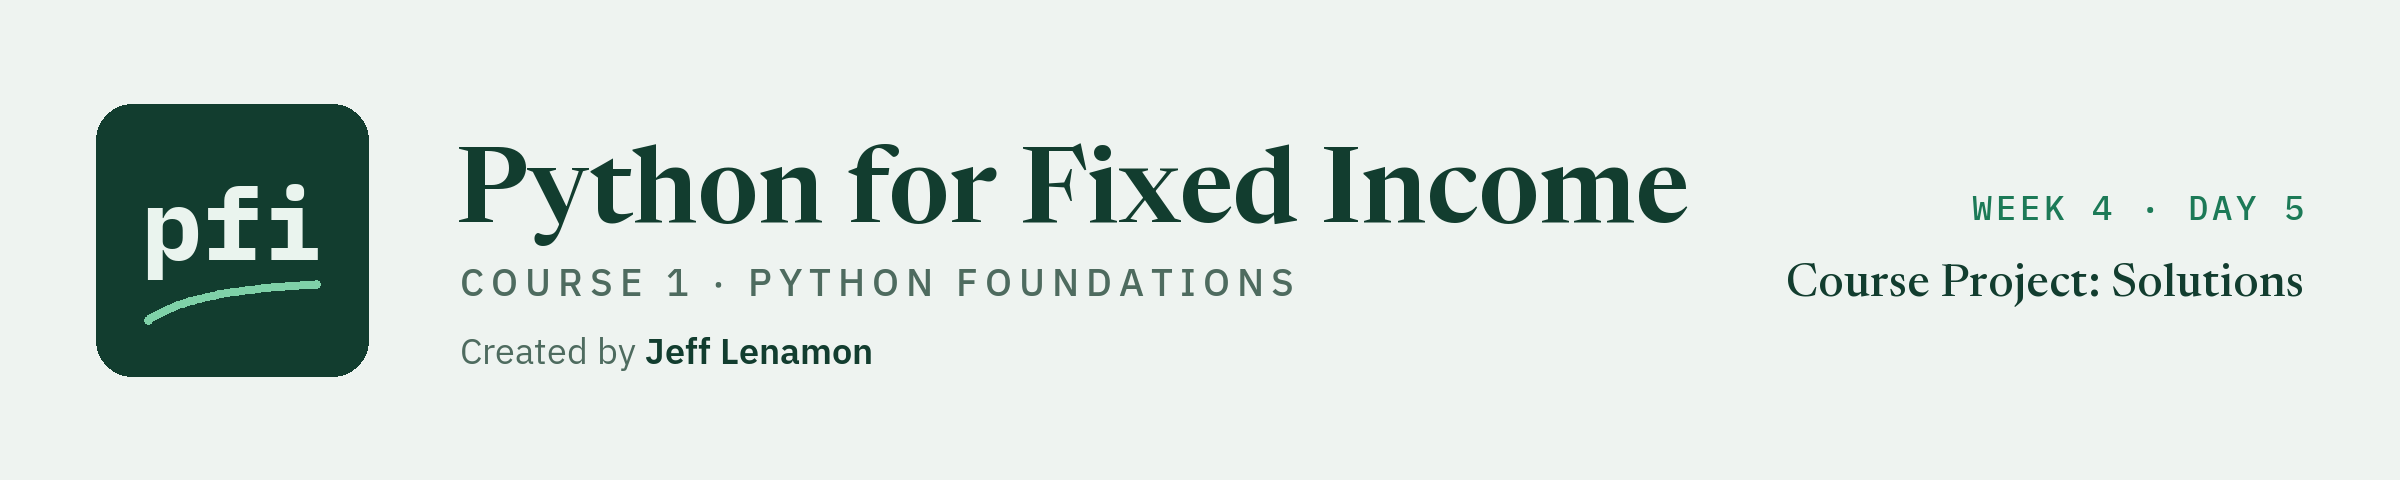

# Course Project: Solutions

Week 4, Day 5. The worked version of the Course 1 project: every question answered with code, its output, and what the output shows. Write your own answers and your own page first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day5/course1_project_solutions.ipynb)

## Setup

The same three cells as the project notebook.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in the Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

In [2]:
# the repo's data folder on your machine; in Colab, GitHub, as in pandas Part 1
if os.path.exists('../../../data/project_holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
# raw is the extract exactly as it arrived: nothing you write changes it
raw = pd.read_csv(data_folder + 'project_holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
benchmark = pd.read_csv(data_folder + 'benchmark.csv')
# the cover note's control totals
expected_bonds = 206
expected_face = 507_250_000
expected_value = 509_928_477.50


def headline(label, table):
    # the headline numbers, printed before and after every fix, as in the EDA notebook
    print(f"{label}: {len(table):,} rows | face {table['par_held'].sum():,} | "
          f"market value {table['market_value'].sum():,.2f} | mean OAS {table['oas'].mean():.2f}")


print('ratings', ratings.shape, '| benchmark', benchmark.shape)

ratings (18, 4) | benchmark (821, 19)


In [3]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written here
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    # a number is rounded to the places the question asks for, so 7 and 7.0 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + '|' + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have ' + str(answer))

## 1 The Structure of the Data

### 1.1 Rows, Columns, and Identifiers

In [4]:
# shape is a pair: (rows, columns)
answer_1_1a = raw.shape
# nunique() counts the different values in a column
answer_1_1b = raw['cusip'].nunique()
print(answer_1_1a, raw['as_of_date'].nunique(), answer_1_1b)
print(raw['ticker'].nunique(), raw['issuer'].nunique())
raw.head()

(209, 19) 1 206
113 113


,as_of_date,cusip,ticker,issuer,sector,rating,coupon,maturity,price,price_date,accrued,yield_pct,oas,duration,spread_duration,dts,amount_outstanding,par_held,market_value
0,2026-10-30,99080CAE8,BEZE,Bezane Finance,Financials,BBB-,7.000,2032-06-18,106.576,2026-10-30,2.567,5.620,149.0,4.545,4.545,677.2,1650000000,4000000,4365720.0
1,2026-10-30,99049XAE2,BEZH,Bezamyth Machinery,Industrials,B,8.125,2029-04-17,97.242,2026-10-30,0.293,9.402,554.0,2.171,2.171,1202.7,950000000,250000,243837.5
2,2026-10-30,99049XAE2,BEZH,Bezamyth Machinery,Industrials,B,8.125,2029-04-17,97.242,2026-10-30,0.293,9.402,554.0,2.171,2.171,1202.7,950000000,250000,243837.5
3,2026-10-30,99039NAC0,BEZL,Bezoquil Freight,Transportation,BB,5.125,2030-06-03,98.848,2026-10-30,2.093,5.481,151.0,3.169,3.169,478.5,850000000,1500000,1514115.0
4,2026-10-30,99039NAF3,BEZL,Bezoquil Freight,Transportation,BB,4.875,2035-11-15,93.286,2026-10-30,2.234,5.841,153.0,6.975,6.975,1067.2,300000000,3750000,3582000.0


In [5]:
check('Question 1.1 shape', answer_1_1a, 'efc00d12fce0')
check('Question 1.1 CUSIPs', answer_1_1b, '8e37a58aa0ec', places=0)

Question 1.1 shape: correct
Question 1.1 CUSIPs: correct


209 rows and 19 columns, where the cover note says 206 bonds: one row should be one bond held, valued on the as-of date.
There is one as-of date and 206 different CUSIPs in 209 rows, so some CUSIP is there more than once; 113 tickers match 113 issuers.

## 2 Data Types

### 2.1 The Type of Each Column

In [6]:
print(raw.dtypes)
# describe() keeps only the columns held as numbers, so its columns count them
answer_2_1 = len(raw.describe().columns)
print(answer_2_1)

as_of_date                str
cusip                     str
ticker                    str
issuer                    str
sector                    str
rating                    str
coupon                float64
maturity                  str
price                 float64
price_date                str
accrued               float64
yield_pct             float64
oas                   float64
duration              float64
spread_duration       float64
dts                   float64
amount_outstanding      int64
par_held                int64
market_value          float64
dtype: object
11


In [7]:
check('Question 2.1', answer_2_1, '8ed934a15453', places=0)

Question 2.1: correct


11 columns are numbers, nine `float64` and two `int64`; the dates `as_of_date`, `maturity`, and `price_date` are text, `str`.
`oas` is `float64` though the dictionary calls it a whole number of basis points: section 3 finds why.

### 2.2 A Working Copy With Real Dates

In [8]:
# book is the working copy; raw is not changed again
book = raw.copy()
answer_2_2 = 0
for column in ['as_of_date', 'maturity', 'price_date']:
    # errors='coerce' turns text that is not a date into a missing date, so count those
    book[column] = pd.to_datetime(book[column], format='%Y-%m-%d', errors='coerce')
    answer_2_2 = answer_2_2 + book[column].isna().sum()
    print(column, book[column].min().date(), book[column].max().date())

as_of_date 2026-10-30 2026-10-30
maturity 2019-10-21 2056-07-24
price_date 2026-10-30 2026-10-30


In [9]:
check('Question 2.2', answer_2_2, 'eae021f63e10', places=0)

Question 2.2: correct


No date failed to convert, and both `as_of_date` and `price_date` hold one date, 2026-10-30.
The earliest maturity, 2019-10-21, is seven years before the as-of date: section 3 tests it as a rule.

## 3 Data Quality: Test the Extract

### 3.1 The File Against the Cover Note

In [10]:
headline('As received', raw)
# each total less the cover note's
answer_3_1 = len(raw) - expected_bonds
print('rows:', answer_3_1, ' face:', raw['par_held'].sum() - expected_face)
print('market value:', round(raw['market_value'].sum() - expected_value, 2))

As received: 209 rows | face 507,000,000 | market value 516,229,847.50 | mean OAS 192.18
rows: 3  face: -250000
market value: 6301370.0


In [11]:
check('Question 3.1', answer_3_1, '937c431e769f', places=0)

Question 3.1: correct


The file has 3 rows and 6,301,370.00 dollars of market value too many, and 250,000 dollars of face too few.
Extra rows would add face as well as value, so at least two problems are at work.

### 3.2 Rule 1: One Row for Each Bond

In [12]:
# duplicated() marks a row that matches an earlier row in every column
copies = book.duplicated()
answer_3_2 = copies.sum()
print(answer_3_2, book.loc[copies, 'par_held'].sum())
print(round(book.loc[copies, 'market_value'].sum(), 2))
# keep=False marks the original as well as its copy
book.loc[book.duplicated(keep=False), ['cusip', 'ticker', 'par_held', 'market_value']]

3 6250000
6301370.0


,cusip,ticker,par_held,market_value
1,99049XAE2,BEZH,250000,243837.5
2,99049XAE2,BEZH,250000,243837.5
175,99085HAA0,TROR,2250000,2244870.0
176,99085HAA0,TROR,2250000,2244870.0
186,99006GAC4,VYRH,3750000,3812662.5
187,99006GAC4,VYRH,3750000,3812662.5


In [13]:
check('Question 3.2', answer_3_2, '68eb8d661dc0', places=0)

Question 3.2: correct


3 rows are exact copies, each directly below its original, at rows 2, 176, and 187.
They carry 6,250,000 dollars of face and 6,301,370.00 of market value: the market value gap of 3.1, to the cent.

### 3.3 Rule 2: Identifiers

In [14]:
# fullmatch() is True when the whole value fits: nine capital letters or digits
answer_3_3a = (~book['cusip'].str.fullmatch(r'[A-Z0-9]{9}')).sum()
# with the exact copies gone, a CUSIP still repeated would have two sets of values
print(answer_3_3a, book.drop_duplicates()['cusip'].duplicated().sum())
answer_3_3b = (~book['cusip'].isin(benchmark['cusip'])).sum()
print(answer_3_3b)

0 0
0


In [15]:
check('Question 3.3 shape', answer_3_3a, '62a24f0a3305', places=0)
check('Question 3.3 benchmark', answer_3_3b, '49f7ac431691', places=0)

Question 3.3 shape: correct
Question 3.3 benchmark: correct


All three tests pass: 0 bad shapes, 0 CUSIPs repeated with other values, 0 missing from the benchmark.
A clean result is a result, and it goes in the page.

### 3.4 Rule 3: The Face Held

In [16]:
bad_face = book['par_held'] <= 0
answer_3_4 = bad_face.sum()
print(answer_3_4, book.loc[bad_face, 'par_held'].sum())
book.loc[bad_face, ['cusip', 'ticker', 'price', 'accrued', 'par_held', 'market_value']]

2 -3250000


,cusip,ticker,price,accrued,par_held,market_value
138,99032GAB4,QUEL,102.225,1.576,-1250000,1297512.5
190,99042QAA2,VYRR,100.994,1.666,-2000000,2053200.0


In [17]:
check('Question 3.4', answer_3_4, 'b8711bc55ec3', places=0)

Question 3.4: correct


QUEL and VYRR hold -1,250,000 and -2,000,000 of face against positive market values.
Made positive, they add 6,500,000 of face: less the copies' 6,250,000, that is the 250,000 the file is short.

### 3.5 Rule 4: The Maturity

In [18]:
bad_maturity = book['maturity'] <= book['as_of_date']
answer_3_5 = bad_maturity.sum()
book.loc[bad_maturity, ['cusip', 'ticker', 'coupon', 'maturity', 'duration']]

,cusip,ticker,coupon,maturity,duration
148,99046UAD3,SKEN,9.25,2019-10-21,2.55


In [19]:
check('Question 3.5', answer_3_5, '9b6cbc9b0cc7', places=0)

Question 3.5: correct


SKEN `99046UAD3` matured on 2019-10-21 yet carries a duration of 2.55 years: the maturity is the column that is wrong.

### 3.6 Rule 5: The Tie-Out

In [20]:
# market value worked out from three other columns; .abs() drops the sign of the gap
gap = (book['par_held'] * (book['price'] + book['accrued']) / 100 - book['market_value']).abs()
no_tie = gap > 1
answer_3_6 = no_tie.sum()
print(answer_3_6, round(gap[~no_tie].max(), 2))
print(book.loc[~no_tie, 'price'].min(), book.loc[~no_tie, 'price'].max())
book.loc[no_tie, ['ticker', 'coupon', 'yield_pct', 'price', 'accrued', 'par_held', 'market_value']]

5 0.0
63.522 126.427


,ticker,coupon,yield_pct,price,accrued,par_held,market_value
138,QUEL,6.375,6.027,102.22500,1.576,-1250000,1297512.5
174,TROE,6.375,5.791,1.01860,2.639,2750000,2873722.5
190,VYRR,4.875,4.472,100.99400,1.666,-2000000,2053200.0
200,XANL,10.625,10.389,1.01346,2.833,3250000,3385817.5
203,YARN,4.375,4.937,9824.30000,0.304,1250000,1231837.5


In [21]:
check('Question 3.6', answer_3_6, 'd80dba792a53', places=0)

Question 3.6: correct


5 rows do not tie out, and in the other 204 the largest gap is 0.00 dollars.
Two are the negative faces of 3.4; the other three have prices of 1.0186, 1.01346, and 9,824.3, where the rest run from 63.522 to 126.427.

### 3.7 Rule 6: Sector Names

In [22]:
print(book['sector'].value_counts())
off_list = ~book['sector'].isin(benchmark['sector'])
answer_3_7 = off_list.sum()
# tolist() prints each value in quotes, so a space at either end shows
print(benchmark['sector'].nunique(), answer_3_7, book.loc[off_list, 'sector'].tolist())

sector
Financials         27
Materials          26
Telecom            24
Consumer           23
Transportation     21
Health Care        19
Industrials        18
Energy             16
Utilities          13
Technology         13
utilities           1
MATERIALS           1
Transportation      1
 consumer           1
industrials         1
TECHNOLOGY          1
Energy              1
 industrials        1
telecom             1
Name: count, dtype: int64
10 9 ['utilities', 'MATERIALS', 'Transportation ', ' consumer', 'industrials', 'TECHNOLOGY', 'Energy ', ' industrials', 'telecom']


In [23]:
check('Question 3.7', answer_3_7, '1b007be9b4e9', places=0)

Question 3.7: correct


The benchmark has 10 names and the extract 19 values: 9 rows hold a benchmark name in other capitals or with a stray space, and no new sector.

### 3.8 Rule 7: Missing Numbers

In [24]:
missing = book.isna().sum()
answer_3_8a = missing.sum()
# a row with a gap has a count of missing cells above 0 across the row (axis=1)
gaps = book[book.isna().sum(axis=1) > 0]
answer_3_8b = round(gaps['market_value'].sum() / expected_value * 100, 2)
print(missing[missing > 0], answer_3_8a, answer_3_8b)
dropped = book.dropna()
print('dropped:', len(dropped), 'rows,', round(dropped['market_value'].sum(), 2), 'dollars')
gaps[['cusip', 'ticker', 'sector', 'rating', 'spread_duration', 'dts', 'market_value']]

oas    4
dtype: int64 4 3.33
dropped: 205 rows, 499272540.0 dollars


,cusip,ticker,sector,rating,spread_duration,dts,market_value
82,99078AAE6,HESA,Consumer,A-,6.685,715.3,4886182.5
96,99087JAC0,KRIX,Telecom,BBB-,4.631,889.2,4682012.5
99,99114KAA8,LORE,Technology,BB-,1.810,689.6,2753162.5
147,99079BAC7,RULR,Utilities,A+,7.753,441.9,4635950.0


In [25]:
check('Question 3.8 missing cells', answer_3_8a, '42cf353ad1b9', places=0)
check('Question 3.8 share', answer_3_8b, 'e3f4ef2ffa88', places=2)

Question 3.8 missing cells: correct
Question 3.8 share: correct


Only `oas` has gaps, 4 of them, which is why it is `float64`: `NaN` is a decimal.
The four are 3.33 percent of the cover note's value, in four sectors and four ratings with no pattern; dropping them would remove four bonds the desk owns.

### 3.9 Price Dates and Six More Tests

In [26]:
answer_3_9a = (book['price_date'] != book['as_of_date']).sum()
# one mask per test; True marks a row that breaks it
tests = [book['price'] <= 0, book['coupon'] <= 0, book['duration'] <= 0,
         book['par_held'] > book['amount_outstanding'],
         ~book['rating'].isin(ratings['rating']),
         book['ticker'] != book['ticker'].str.strip().str.upper()]
# int() turns each count into a plain whole number for printing
counts = [int(test.sum()) for test in tests]
answer_3_9b = sum(counts)
print(answer_3_9a, counts, answer_3_9b)

0 [0, 0, 0, 0, 0, 0] 0


In [27]:
check('Question 3.9 price dates', answer_3_9a, 'adc58bb8921d', places=0)
check('Question 3.9 six tests', answer_3_9b, '30a63952bf8a', places=0)

Question 3.9 price dates: correct
Question 3.9 six tests: correct


Every price is dated 2026-10-30 and all six tests pass: September's stale prices and untidy tickers are not in this file.

## 4 Data Quality: Decide, Fix, and Package

### 4.1 Decide and Fix

**Decision 1.** Remove the 3 repeated rows, keeping the first of each.

Evidence: they match an earlier row in all 19 columns, and their market value is the excess over the control total.

In [28]:
headline('Before', book)
# drop_duplicates() keeps the first of each; reset_index(drop=True) renumbers from 0
book = book.drop_duplicates().reset_index(drop=True)
headline('After', book)
print('face less cover note:', book['par_held'].sum() - expected_face)

Before: 209 rows | face 507,000,000 | market value 516,229,847.50 | mean OAS 192.18
After: 206 rows | face 500,750,000 | market value 509,928,477.50 | mean OAS 190.21
face less cover note: -6500000


209 rows became 206 and the market value ties; the face gap grew from -250,000 to -6,500,000, the shortfall the copies had hidden.

**Decision 2.** Tidy every sector to the benchmark's spelling.

Evidence: each of the 9 failing values becomes a benchmark name once stripped and capitalized.

In [29]:
before = book.groupby('sector')['market_value'].sum()
# no spaces at the ends, a capital at the start of each word
book['sector'] = book['sector'].str.strip().str.title()
after = book.groupby('sector')['market_value'].sum()
print(book['sector'].nunique(), before['Industrials'], after['Industrials'])
print(set(book['sector']) == set(benchmark['sector']))

10 41916605.0 50287460.0
True


19 values became the benchmark's 10, and Industrials grew from 41,916,605 to 50,287,460 dollars: a sector report on the raw column would have been short with no error.

**Decision 3.** Make the 2 negative faces positive.

Evidence: the market value in each row is what the positive face gives, to the cent.

In [30]:
bad_face = book['par_held'] <= 0
# the market value the positive face gives, beside the file's
worked = book.loc[bad_face, 'par_held'].abs() * (book.loc[bad_face, 'price']
                                                + book.loc[bad_face, 'accrued']) / 100
print(worked.tolist(), book.loc[bad_face, 'market_value'].tolist())
headline('Before', book)
book.loc[bad_face, 'par_held'] = book.loc[bad_face, 'par_held'].abs()
headline('After', book)

[1297512.4999999998, 2053200.0] [1297512.5, 2053200.0]
Before: 206 rows | face 500,750,000 | market value 509,928,477.50 | mean OAS 190.21
After: 206 rows | face 507,250,000 | market value 509,928,477.50 | mean OAS 190.21


The face is now 507,250,000 dollars, the cover note's figure.

**Decision 4.** Put the 3 prices back into per 100 of face.

Evidence: the price implied by market value, face, and accrued is the file's price with the decimal point two places out.

In [31]:
# the price the other three columns imply
implied = book['market_value'] / book['par_held'] * 100 - book['accrued']
too_low = book['price'] < 10
too_high = book['price'] > 1000
print(book.loc[too_low | too_high, ['ticker', 'coupon', 'yield_pct', 'price']]
      .assign(implied=implied.round(3)))
print(round(book['price'].mean(), 3), round(book['price'].median(), 3))
book.loc[too_low, 'price'] = (book.loc[too_low, 'price'] * 100).round(3)
book.loc[too_high, 'price'] = (book.loc[too_high, 'price'] / 100).round(3)
print(round(book['price'].mean(), 3), round(book['price'].median(), 3))

    ticker  coupon  yield_pct       price  implied
173   TROE   6.375      5.791     1.01860  101.860
197   XANL  10.625     10.389     1.01346  101.346
200   YARN   4.375      4.937  9824.30000   98.243
145.043 99.389
98.806 99.474


The implied prices are 101.86, 101.346, and 98.243, each on the side of par its coupon and yield predict.
The mean price falls from 145.043 to 98.806; the median barely moves, 99.389 to 99.474.

**Decision 5.** Replace the 2019 maturity with the benchmark's for the same CUSIP.

Evidence: the same ticker and the 9.25 percent coupon in both files, and a duration of 2.55 years that fits 2029.

In [32]:
bad_maturity = book['maturity'] <= book['as_of_date']
bad_cusip = book.loc[bad_maturity, 'cusip'].iloc[0]
benchmark_row = benchmark[benchmark['cusip'] == bad_cusip]
print(benchmark_row[['cusip', 'ticker', 'coupon', 'maturity']])
# the benchmark's maturity is text, so make it a date first
book.loc[bad_maturity, 'maturity'] = pd.Timestamp(benchmark_row['maturity'].iloc[0])
print(book['maturity'].min().date())

         cusip ticker  coupon    maturity
237  99046UAD3   SKEN    9.25  2029-10-21
2027-10-02


The earliest maturity is now 2027-10-02, after the as-of date.

**Decision 6.** Fill the 4 missing OAS values with `dts` over `spread_duration`, rounded.

Evidence: the rule gives the file's OAS in every one of the 202 complete rows.

In [33]:
worked_out_oas = (book['dts'] / book['spread_duration']).round()
present = book['oas'].notna()
print(present.sum(), (worked_out_oas[present] != book.loc[present, 'oas']).sum())
print(worked_out_oas[~present].tolist())
headline('Before', book)
# fillna() given a column fills each gap from the same row; then whole numbers again
book['oas'] = book['oas'].fillna(worked_out_oas).astype(int)
headline('After', book)

202 0
[107.0, 192.0, 381.0, 57.0]
Before: 206 rows | face 507,250,000 | market value 509,928,477.50 | mean OAS 190.21
After: 206 rows | face 507,250,000 | market value 509,928,477.50 | mean OAS 190.09


The four gaps become 107, 192, 381, and 57 basis points, and the mean OAS moves from 190.21 over 202 bonds to 190.09 over 206.
Nothing needed flagging: every error had its evidence in the files.

In [34]:
# every test of section 3, on the corrected table
gap = (book['par_held'] * (book['price'] + book['accrued']) / 100 - book['market_value']).abs()
failing = [book.duplicated(), ~book['cusip'].str.fullmatch(r'[A-Z0-9]{9}'),
           ~book['cusip'].isin(benchmark['cusip']), book['par_held'] <= 0,
           book['maturity'] <= book['as_of_date'], gap > 1,
           ~book['sector'].isin(benchmark['sector']), book.isna().sum(axis=1) > 0,
           book['price_date'] != book['as_of_date'], book['price'] <= 0, book['coupon'] <= 0,
           book['duration'] <= 0, book['par_held'] > book['amount_outstanding'],
           ~book['rating'].isin(ratings['rating']),
           book['ticker'] != book['ticker'].str.strip().str.upper()]
answer_4_1 = sum([test.sum() for test in failing])
print(answer_4_1, round(gap.max(), 2))

0 0.0


In [35]:
check('Question 4.1', answer_4_1, 'acca33222a1d', places=0)

Question 4.1: correct


No row fails any test.
Only the copies and the negative faces touched a control total: the prices, sectors, maturity, and OAS gaps would have passed a check of totals alone.

### Checkpoint: the Cleaned Table

In [36]:
# the cleaned book against the cover note and the decisions the worked version made
if book is ...:
    print('Checkpoint: not attempted yet')
else:
    check('Checkpoint rows', len(book), 'd5ed44cc564e', places=0)
    check('Checkpoint face', book['par_held'].sum(), '254fb34186a5', places=0)
    check('Checkpoint market value', book['market_value'].sum(), '5c6137e7ec20', places=2)
    check('Checkpoint different sectors', book['sector'].nunique(), 'c7854488271a', places=0)
    check('Checkpoint missing cells', book.isna().sum().sum(), '53b200a15764', places=0)
    check('Checkpoint mean OAS', book['oas'].mean(), '35ec3732ae02', places=2)
    check('Checkpoint mean price', book['price'].mean(), 'cd707ccf0646', places=3)
    check('Checkpoint raw is unchanged', raw.shape, '9aa4001604ba')

### The Three Gaps, Closed

Checkpoint rows: correct
Checkpoint face: correct
Checkpoint market value: correct
Checkpoint different sectors: correct
Checkpoint missing cells: correct
Checkpoint mean OAS: correct
Checkpoint mean price: correct
Checkpoint raw is unchanged: correct


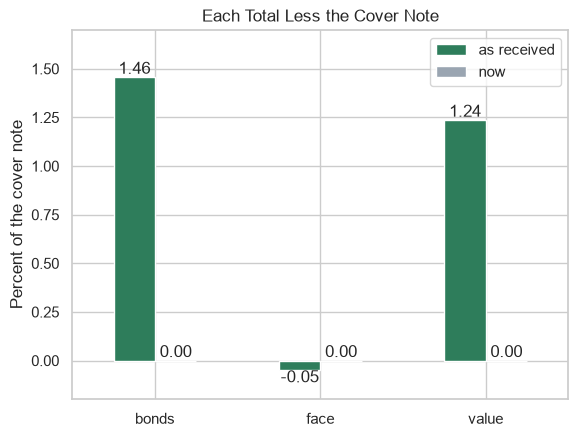

In [37]:
# written for you: each total against the cover note, in percent (Analyzing Text Part 2's .div)
if book is ...:
    print('Chart: not attempted yet')
else:
    received = [len(raw), raw['par_held'].sum(), raw['market_value'].sum()]
    now = [len(book), book['par_held'].sum(), book['market_value'].sum()]
    totals = pd.DataFrame({'as received': received, 'now': now}, index=['bonds', 'face', 'value'])
    gaps = totals.div([expected_bonds, expected_face, expected_value], axis=0) * 100 - 100
    chart = gaps.plot.bar(rot=0, ylim=(-0.2, 1.7), title='Each Total Less the Cover Note',
                          ylabel='Percent of the cover note')
    for bars in chart.containers:
        chart.bar_label(bars, fmt='%.2f')
    plt.show()

As received the file was 1.46 percent over on bonds, 0.05 percent under on face, and 1.24 percent over on market value; now every gap is 0.

### 4.2 The Cleaning as a Function

In [38]:
def clean_extract(raw, benchmark):
    """Apply the desk's decisions to a month-end extract and return the cleaned table.

    raw is the extract as it arrived and benchmark is the benchmark file; neither is changed.
      1. Exact duplicate rows are removed, keeping the first of each.
      2. Sector names are tidied to the benchmark's spelling.
      3. A negative face held becomes the positive amount.
      4. A price a hundredth or a hundred times its size goes back to per 100 of face.
      5. A maturity on or before the as-of date becomes the benchmark's for that CUSIP.
      6. A missing OAS is DTS divided by spread duration, to a whole basis point.
    """
    book = raw.copy()
    for column in ['as_of_date', 'maturity', 'price_date']:
        book[column] = pd.to_datetime(book[column], format='%Y-%m-%d')
    book = book.drop_duplicates().reset_index(drop=True)
    book['sector'] = book['sector'].str.strip().str.title()
    book['par_held'] = book['par_held'].abs()
    too_low = book['price'] < 10
    too_high = book['price'] > 1000
    book.loc[too_low, 'price'] = (book.loc[too_low, 'price'] * 100).round(3)
    book.loc[too_high, 'price'] = (book.loc[too_high, 'price'] / 100).round(3)
    # map() looks up each matured row's CUSIP in the benchmark's maturities
    matured = book['maturity'] <= book['as_of_date']
    benchmark_maturity = benchmark.set_index('cusip')['maturity']
    book.loc[matured, 'maturity'] = pd.to_datetime(
        book.loc[matured, 'cusip'].map(benchmark_maturity))
    worked_out_oas = (book['dts'] / book['spread_duration']).round()
    book['oas'] = book['oas'].fillna(worked_out_oas).astype(int)
    # the rules the function promises, tested before the table is handed back
    assert book['cusip'].is_unique, 'a CUSIP is still repeated'
    assert book.isna().sum().sum() == 0, 'a cell is still missing'
    assert set(book['sector']) == set(benchmark['sector']), 'a sector is off the benchmark list'
    return book


cleaned = clean_extract(raw, benchmark)
# the cover note's three control totals; an assert that passes prints nothing
assert len(cleaned) == expected_bonds, f'{len(cleaned)} rows against {expected_bonds}'
assert cleaned['par_held'].sum() == expected_face, 'face does not match the cover note'
assert round(cleaned['market_value'].sum(), 2) == expected_value, 'market value is off'
# equals() is True when two tables match in every value and type, as in the EDA notebook
print(cleaned.equals(book), len(raw))

True 209


In [39]:
if cleaned is ...:
    print('Question 4.2: not attempted yet')
else:
    check('Question 4.2 rows', len(cleaned), 'e5178efc63d4', places=0)
    check('Question 4.2 face', cleaned['par_held'].sum(), '6613f6221e2c', places=0)
    check('Question 4.2 market value', cleaned['market_value'].sum(), '6594eed8b78e', places=2)
    check('Question 4.2 mean OAS', cleaned['oas'].mean(), 'f3ba04a128b9', places=2)
    check('Question 4.2 mean price', cleaned['price'].mean(), 'ef25b86639bb', places=3)
    check('Question 4.2 same as book', cleaned.equals(book), '6466c1cc0468')

Question 4.2 rows: correct
Question 4.2 face: correct
Question 4.2 market value: correct
Question 4.2 mean OAS: correct
Question 4.2 mean price: correct
Question 4.2 same as book: correct


One call rebuilds the cleaned table from the file as it arrived, equal to `book` in all 19 columns, and `raw` still has 209 rows.
The asserts inside test rules; the asserts after the call test the cover note, which changes every month while the decisions do not.

## 5 Summary Statistics

### 5.1 The Rating Scale

In [40]:
rows_before = len(book)
# a left merge keeps every bond; validate= stops if a rating is on the scale twice
book = pd.merge(book, ratings, on='rating', how='left', validate='many_to_one')
print(rows_before, len(book), book['grade'].isna().sum())
print(book['grade'].value_counts())
answer_5_1 = (book['grade'] == 'High Yield').sum()

206 206 0
grade
Investment Grade    130
High Yield           76
Name: count, dtype: int64


In [41]:
check('Question 5.1', answer_5_1, 'c9f4439c8ead', places=0)

Question 5.1: correct


206 rows before and after, every rating on the scale: 130 Investment Grade and 76 High Yield.

### 5.2 Summary, Mean, Median, and Skew

In [42]:
columns = ['coupon', 'price', 'yield_pct', 'oas', 'duration', 'market_value']
answer_5_2a = book['oas'].median()
print(book[columns].describe().round(2))
# .T turns the table so that each column of the book is a row
print(book[columns + ['dts']].agg(['mean', 'median', 'skew']).T.round(2))
answer_5_2b = round(book['oas'].skew(), 2)

       coupon   price  yield_pct      oas  duration  market_value
count  206.00  206.00     206.00   206.00    206.00        206.00
mean     5.96   98.81       6.12   190.09      6.33    2475380.96
std      1.69    7.66       2.01   198.57      3.42    1442028.31
min      2.75   63.52       4.08    19.00      0.88     209600.00
25%      4.75   95.22       5.02    81.50      3.63    1262515.62
50%      5.62   99.47       5.54   138.50      6.19    2327860.00
75%      7.00  102.67       6.38   208.75      7.89    3704900.00
max     11.00  126.43      18.42  1463.00     15.96    5442600.00
                    mean      median  skew
coupon              5.96        5.62  0.96
price              98.81       99.47 -0.58
yield_pct           6.12        5.54  3.29
oas               190.09      138.50  3.47
duration            6.33        6.19  0.53
market_value  2475380.96  2327860.00  0.28
dts              1126.21      773.00  2.13


In [43]:
check('Question 5.2 median OAS', answer_5_2a, '0d93273ea756', places=1)
check('Question 5.2 skew', answer_5_2b, 'dfeb3da67e98', places=2)

Question 5.2 median OAS: correct
Question 5.2 skew: correct


Every range is possible for a bond: prices from 63.52 to 126.43, durations from 0.88 to 15.96 years, OAS from 19 to 1,463 basis points with a median of 138.5.
The OAS has the longest right tail, a skew of 3.47 with the mean 190.09 above the median; price alone leans left, -0.58.

### 5.3 Counts by Category

[3, 9, 58, 60, 50, 20, 6]


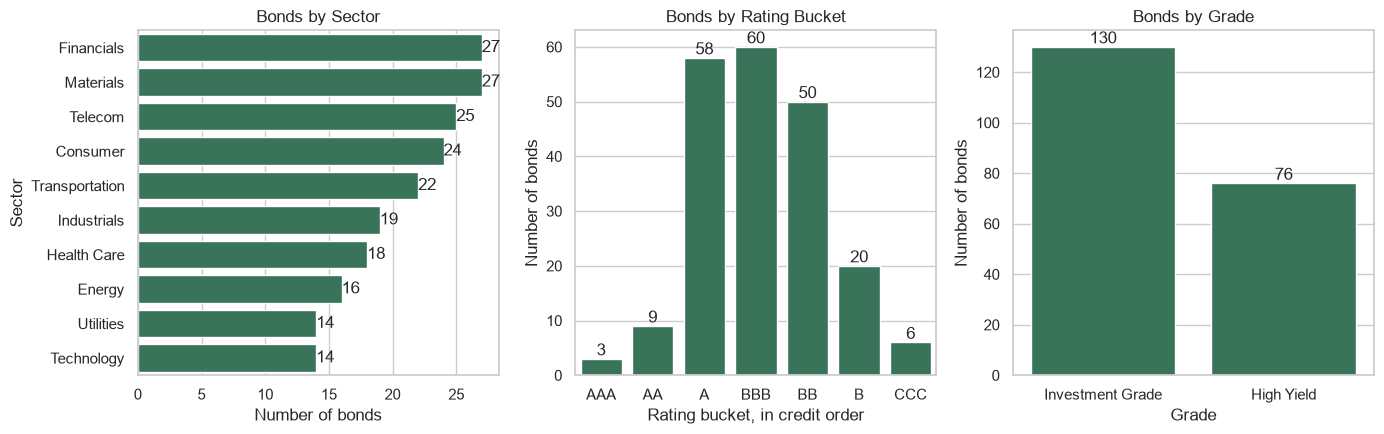

In [44]:
# the seven buckets in credit order, from the scale sorted by score
bucket_order = ratings.sort_values('score')['bucket'].unique().tolist()
bucket_counts = book['bucket'].value_counts().loc[bucket_order]
answer_5_3 = bucket_counts.idxmax()
print(bucket_counts.tolist())
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
sns.countplot(data=book, y='sector', order=book['sector'].value_counts().index, ax=axes[0])
sns.countplot(data=book, x='bucket', order=bucket_order, ax=axes[1])
sns.countplot(data=book, x='grade', order=['Investment Grade', 'High Yield'], ax=axes[2])
for ax, title in zip(axes, ['Bonds by Sector', 'Bonds by Rating Bucket', 'Bonds by Grade']):
    ax.bar_label(ax.containers[0])
    ax.set_title(title)
# each axis named in words, not the column names seaborn writes
axes[0].set_xlabel('Number of bonds')
axes[0].set_ylabel('Sector')
axes[1].set_xlabel('Rating bucket, in credit order')
axes[1].set_ylabel('Number of bonds')
axes[2].set_xlabel('Grade')
axes[2].set_ylabel('Number of bonds')
plt.tight_layout()
plt.show()

In [45]:
check('Question 5.3', answer_5_3, '16e058800603')

Question 5.3: correct


BBB has the most bonds, 60, then A with 58 and BB with 50; the ends are short, 3 AAA and 6 CCC.
Financials and Materials have 27 bonds each; these are counts, so a 250,000-dollar position weighs as much as a 5,000,000 one.

## 6 One Column at a Time

### 6.1 The Distribution of the OAS

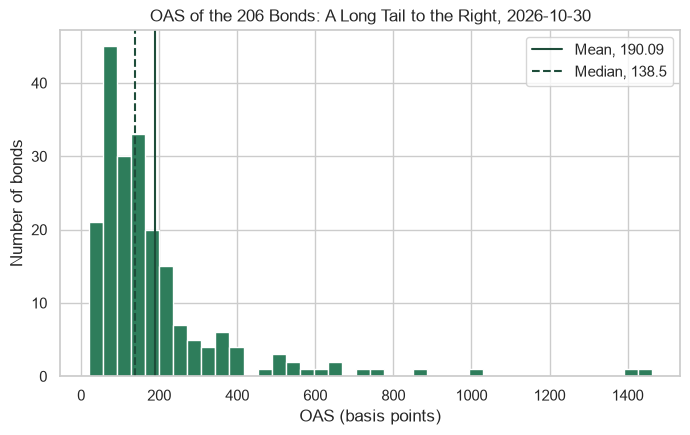

In [46]:
answer_6_1 = (book['oas'] > book['oas'].mean()).sum()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(book['oas'], bins=40)
ax.axvline(book['oas'].mean(), color='#1E4D3A', label=f"Mean, {book['oas'].mean():.2f}")
ax.axvline(book['oas'].median(), color='#1E4D3A', linestyle='--',
           label=f"Median, {book['oas'].median()}")
ax.legend()
ax.set_title('OAS of the 206 Bonds: A Long Tail to the Right, 2026-10-30')
ax.set_xlabel('OAS (basis points)')
ax.set_ylabel('Number of bonds')
plt.show()

In [47]:
check('Question 6.1', answer_6_1, 'cda4c6348719', places=0)

Question 6.1: correct


Only 61 of 206 bonds sit above the mean of 190.09 basis points: the tail out to 1,463 pulls the mean past most of the book.

### 6.2 The IQR Rule

81.5 208.75 127.25 -109.375 399.625 18


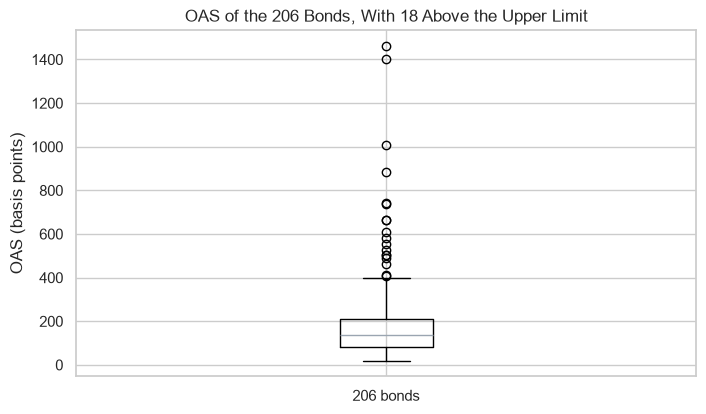

In [48]:
q1, q3 = book['oas'].quantile(0.25), book['oas'].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
answer_6_2a = upper_limit
answer_6_2b = (book['oas'] > upper_limit).sum()
print(q1, q3, q3 - q1, q1 - 1.5 * (q3 - q1), upper_limit, answer_6_2b)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(book['oas'], tick_labels=['206 bonds'])
ax.set_title('OAS of the 206 Bonds, With 18 Above the Upper Limit')
ax.set_ylabel('OAS (basis points)')
plt.show()

In [49]:
check('Question 6.2 upper limit', answer_6_2a, '6b59303d0caa', places=3)
check('Question 6.2 bonds flagged', answer_6_2b, 'cae9f4b76f82', places=0)

Question 6.2 upper limit: correct
Question 6.2 bonds flagged: correct


The quartiles are 81.5 and 208.75 basis points, an IQR of 127.25 and an upper limit of 399.625; 18 bonds sit above it and none below the lower limit, -109.375.

### 6.3 Errors or Real Bonds?

In [50]:
wide = book['oas'] > upper_limit
answer_6_3 = round(book.loc[wide, 'market_value'].sum() / book['market_value'].sum() * 100, 2)
print(answer_6_3, book.loc[wide, 'score'].min(), book.loc[wide, 'score'].max())
# yield less OAS is roughly the Treasury yield a bond is measured against
base = book['yield_pct'] - book['oas'] / 100
print(round(base[wide].min(), 3), round(base[wide].max(), 3))
print(round(base[~wide].min(), 3), round(base[~wide].max(), 3))
book.loc[wide, ['ticker', 'rating', 'coupon', 'price', 'yield_pct', 'oas']].sort_values(
    'oas', ascending=False)

7.62 14 18
3.731 4.584
3.68 4.585


,ticker,rating,coupon,price,yield_pct,oas
68,FESR,CCC+,10.750,88.780,18.415,1463
17,CLDB,B,9.500,63.522,18.300,1403
135,PRAN,CCC+,11.000,75.387,14.664,1008
134,PRAN,CCC+,10.875,88.883,13.116,884
115,NEVN,B-,10.625,92.637,11.826,744
133,PRAN,CCC+,11.000,99.320,11.272,736
114,NEVN,B-,11.000,99.844,11.021,666
74,GALX,B-,9.250,88.521,11.021,662
197,XANL,CCC,10.625,101.346,10.389,607
69,FESR,CCC+,8.875,89.803,10.259,580


In [51]:
check('Question 6.3', answer_6_3, '6ec77e85b8db', places=2)

Question 6.3: correct


All 18 score 14 to 18, B+ or lower, with high yields and coupons or low prices to match their spreads.
Their yield less OAS, 3.731 to 4.584 percent, sits inside the other 188 bonds' band: every column agrees, so they are real.

**Decision 7.** Keep all 18: real bonds with wide spreads, 7.62 percent of the book's market value.

### 6.4 The Distribution of the Price

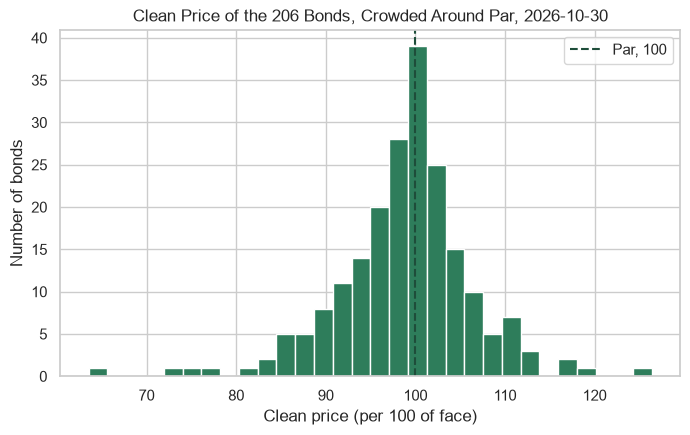

,ticker,rating,coupon,maturity,price,yield_pct,oas
17,CLDB,B,9.50,2034-12-06,63.522,18.300,1403
192,WYXE,BBB+,7.25,2056-07-24,126.427,5.445,86


In [52]:
answer_6_4 = (book['price'] < 100).sum()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(book['price'], bins=30)
ax.axvline(100, color='#1E4D3A', linestyle='--', label='Par, 100')
ax.legend()
ax.set_title('Clean Price of the 206 Bonds, Crowded Around Par, 2026-10-30')
ax.set_xlabel('Clean price (per 100 of face)')
ax.set_ylabel('Number of bonds')
plt.show()
book.loc[[book['price'].idxmin(), book['price'].idxmax()],
         ['ticker', 'rating', 'coupon', 'maturity', 'price', 'yield_pct', 'oas']]

In [53]:
check('Question 6.4', answer_6_4, '1ba8d4146698', places=0)

Question 6.4: correct


114 bonds are below par and 92 at or above it.

The lowest, CLDB at 63.522, is one of the 18 wide bonds; the highest, WYXE at 126.427, is a 2056 bond with a 7.25 percent coupon above its 5.445 percent yield.

Both tie out, so neither is an error.

### 6.5 The Size of the Positions

0.21 5.44 1.07 7.37


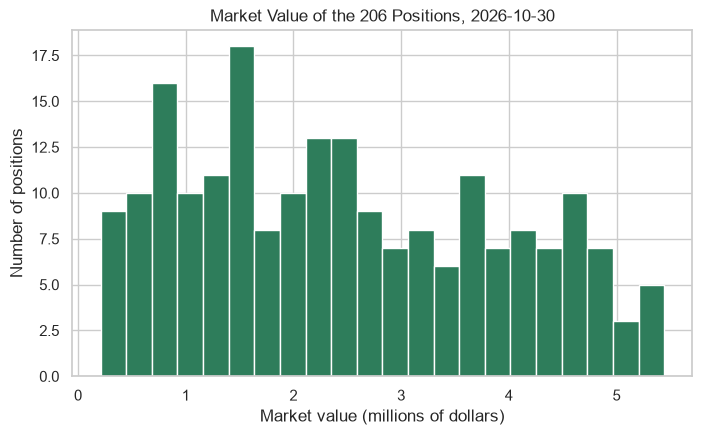

,cusip,ticker,issuer,par_held,market_value
61,99021VAC2,FESA,Feskundra Systems,5000000,5442600.0
105,99076YAC0,LORN,Lorvebran Paper,4750000,5423550.0
183,99024YAE9,VYRE,Vyrerone Metals,4750000,5382747.5


In [54]:
value_mm = book['market_value'] / 1_000_000
answer_6_5 = round(book['market_value'].max() / book['market_value'].sum() * 100, 2)
size_limit = value_mm.quantile(0.75) + 1.5 * (value_mm.quantile(0.75) - value_mm.quantile(0.25))
print(round(value_mm.min(), 2), round(value_mm.max(), 2), answer_6_5, round(size_limit, 2))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(value_mm, bins=22)
ax.set_title('Market Value of the 206 Positions, 2026-10-30')
ax.set_xlabel('Market value (millions of dollars)')
ax.set_ylabel('Number of positions')
plt.show()
book.nlargest(3, 'market_value')[['cusip', 'ticker', 'issuer', 'par_held', 'market_value']]

In [55]:
check('Question 6.5', answer_6_5, 'b905ffad5df0', places=2)

Question 6.5: correct


Positions run from 0.21 to 5.44 million dollars; the largest, FESA, is 1.07 percent of the book.
The IQR limit is 7.37 million, so no position is flagged as large.

## 7 Two or More Columns

### 7.1 Correlations

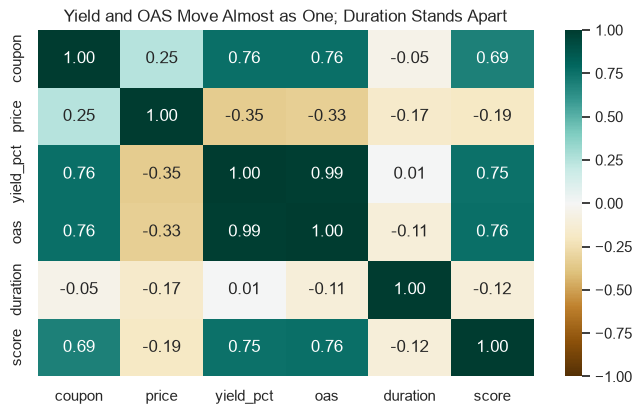

In [56]:
corr_table = book[['coupon', 'price', 'yield_pct', 'oas', 'duration', 'score']].corr()
answer_7_1 = round(corr_table.loc['oas', 'score'], 2)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(corr_table, annot=True, fmt='.2f', cmap='BrBG', vmin=-1, vmax=1, ax=ax)
ax.set_title('Yield and OAS Move Almost as One; Duration Stands Apart')
plt.show()

In [57]:
check('Question 7.1', answer_7_1, '04220a7550f8', places=2)

Question 7.1: correct


Yield and OAS are the strongest pair, 0.99; duration is near zero against everything, -0.11 with OAS and 0.01 with yield.
OAS against score is 0.76, and since the score rises as the rating falls, lower-rated bonds in this file have wider spreads.

### 7.2 Yield Against Duration, by Grade

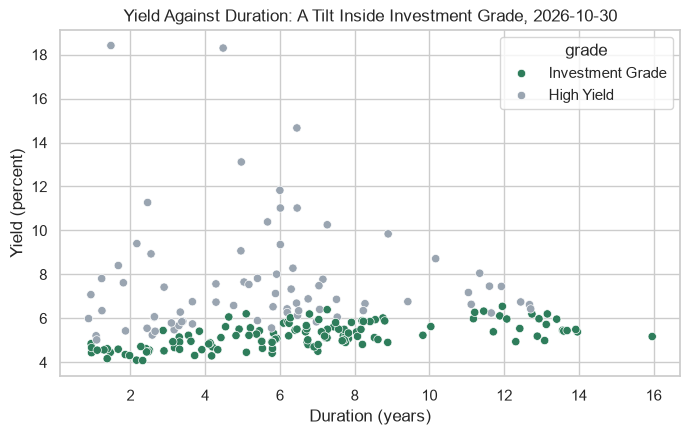

0.01
Investment Grade 130 0.61
High Yield 76 -0.01


In [58]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=book, x='duration', y='yield_pct', hue='grade', ax=ax)
ax.set_title('Yield Against Duration: A Tilt Inside Investment Grade, 2026-10-30')
ax.set_xlabel('Duration (years)')
ax.set_ylabel('Yield (percent)')
plt.show()
print(round(book['duration'].corr(book['yield_pct']), 2))
for grade in ['Investment Grade', 'High Yield']:
    part = book[book['grade'] == grade]
    print(grade, len(part), round(part['duration'].corr(part['yield_pct']), 2))
investment_grade = book[book['grade'] == 'Investment Grade']
answer_7_2 = round(investment_grade['duration'].corr(investment_grade['yield_pct']), 2)

In [59]:
check('Question 7.2', answer_7_2, '187b8b448dbc', places=2)

Question 7.2: correct


The whole book shows 0.01, but the 130 Investment Grade bonds show 0.61 and the 76 High Yield bonds -0.01.
Two groups with different patterns, put in one cloud, show none.

### 7.3 OAS by Rating Bucket

        count  median  min   max
bucket                          
AAA         3    20.0   19    23
AA          9    38.0   22    59
A          58    74.5   42   152
BBB        60   132.5   64   204
BB         50   211.5  131   381
B          20   437.5  229  1403
CCC         6   810.0  580  1463


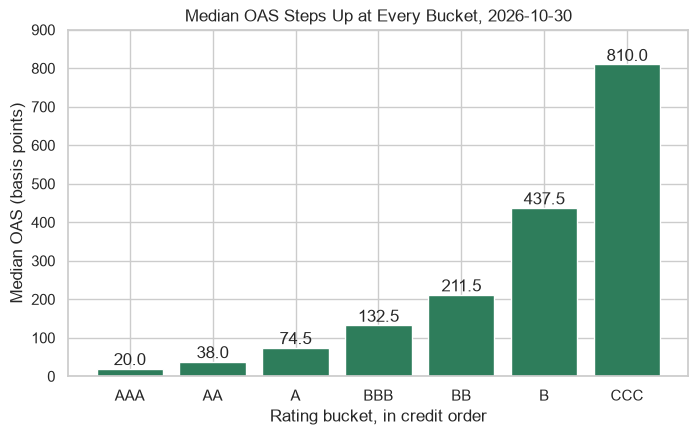

In [60]:
# count, median, lowest, and highest OAS per bucket, put in credit order with .loc
by_bucket = book.groupby('bucket')['oas'].agg(['count', 'median', 'min', 'max']).loc[bucket_order]
print(by_bucket)
answer_7_3 = by_bucket.loc['BBB', 'median']
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(by_bucket.index, by_bucket['median'])
ax.bar_label(bars, fmt='%.1f')
ax.set_ylim(0, 900)
ax.set_title('Median OAS Steps Up at Every Bucket, 2026-10-30')
ax.set_xlabel('Rating bucket, in credit order')
ax.set_ylabel('Median OAS (basis points)')
plt.show()

In [61]:
check('Question 7.3', answer_7_3, '132f7a29d73f', places=1)

Question 7.3: correct


The median rises at every step, 20 basis points for AAA to 810 for CCC, with BBB at 132.5, and the steps widen down the scale.
The ranges overlap: the widest BBB, 204, is wider than the tightest BB, 131; the CCC median rests on 6 bonds.

### 7.4 OAS by Grade

130 89.0 76 259.0 170.0


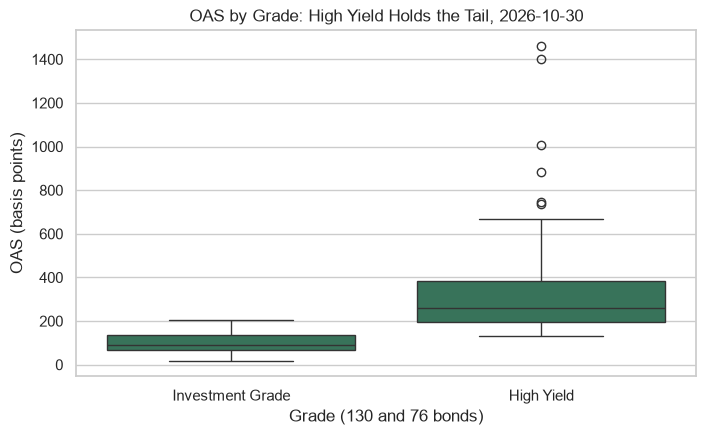

In [62]:
ig_oas = book.loc[book['grade'] == 'Investment Grade', 'oas']
hy_oas = book.loc[book['grade'] == 'High Yield', 'oas']
answer_7_4 = hy_oas.median() - ig_oas.median()
print(len(ig_oas), ig_oas.median(), len(hy_oas), hy_oas.median(), answer_7_4)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=book, x='grade', y='oas', order=['Investment Grade', 'High Yield'], ax=ax)
ax.set_title('OAS by Grade: High Yield Holds the Tail, 2026-10-30')
ax.set_xlabel('Grade (130 and 76 bonds)')
ax.set_ylabel('OAS (basis points)')
plt.show()

In [63]:
check('Question 7.4', answer_7_4, '597d0edf0e6a', places=1)

Question 7.4: correct


The medians are 89.0 basis points for 130 Investment Grade bonds and 259.0 for 76 High Yield, 170.0 apart.
The widest Investment Grade bond, 204, is below the High Yield median: the book's tail is the High Yield tail.

### 7.5 Sector by Grade

509.93 Materials


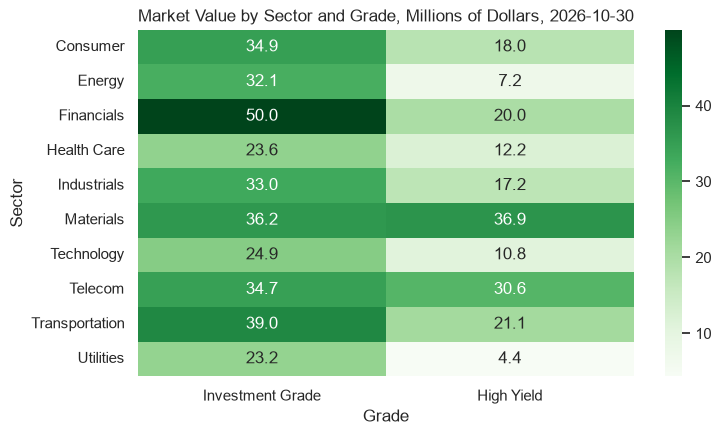

In [64]:
# sectors down, grades across, market value summed in each cell, in millions of dollars
sector_by_grade = pd.pivot_table(book, values='market_value', index='sector', columns='grade',
                                 aggfunc='sum', fill_value=0) / 1_000_000
answer_7_5 = sector_by_grade['High Yield'].idxmax()
print(round(sector_by_grade.sum().sum(), 2), answer_7_5)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(sector_by_grade[['Investment Grade', 'High Yield']], annot=True, fmt='.1f',
            cmap='Greens', ax=ax)
ax.set_title('Market Value by Sector and Grade, Millions of Dollars, 2026-10-30')
ax.set_xlabel('Grade')
ax.set_ylabel('Sector')
plt.show()

In [65]:
check('Question 7.5', answer_7_5, 'a49b15eabb0d')

Question 7.5: correct


The 20 cells add up to 509.93 million dollars, the book.
Materials holds the most High Yield value, 36.93 million against 36.18 of Investment Grade, the one sector where High Yield is larger.

## 8 The Desk's Questions

### 8.1 Weight by Sector, Bucket, and Grade

In [66]:
total_value = book['market_value'].sum()
book['weight_pct'] = book['market_value'] / total_value * 100
print(round(book['weight_pct'].sum(), 2))
by_sector = book.groupby('sector').agg(bonds=('cusip', 'count'),
                                       market_value=('market_value', 'sum'),
                                       weight_pct=('weight_pct', 'sum'))
by_sector = by_sector.sort_values('weight_pct', ascending=False)
print(by_sector.round(2))
by_bucket_value = book.groupby('bucket')['weight_pct'].agg(['count', 'sum']).loc[bucket_order]
print(by_bucket_value.round(2))
by_grade = book.groupby('grade')['weight_pct'].sum()
answer_8_1a = round(by_sector['weight_pct'].max(), 2)
answer_8_1b = round(by_grade['High Yield'], 2)
print(by_grade.round(2))

100.0
                bonds  market_value  weight_pct
sector                                         
Materials          27    73113917.5       14.34
Financials         27    69958000.0       13.72
Telecom            25    65251515.0       12.80
Transportation     22    60036355.0       11.77
Consumer           24    52902217.5       10.37
Industrials        19    50287460.0        9.86
Energy             16    39345555.0        7.72
Health Care        18    35733470.0        7.01
Technology         14    35708670.0        7.00
Utilities          14    27591317.5        5.41
        count    sum
bucket              
AAA         3   2.51
AA          9   3.34
A          58  30.27
BBB        60  28.92
BB         50  23.03
B          20   9.03
CCC         6   2.90
grade
High Yield          34.96
Investment Grade    65.04
Name: weight_pct, dtype: float64


In [67]:
check('Question 8.1 largest sector', answer_8_1a, '2738459af618', places=2)
check('Question 8.1 High Yield', answer_8_1b, 'edaa9854371d', places=2)

Question 8.1 largest sector: correct
Question 8.1 High Yield: correct


Materials is the largest sector at 14.34 percent, then Financials at 13.72; Utilities is smallest at 5.41.
The A bucket outweighs BBB, 30.27 against 28.92 percent, on fewer bonds; High Yield is 34.96 percent of the value and 76 of 206 bonds.

### 8.2 The Ten Largest Issuers

In [68]:
by_issuer = book.groupby('issuer').agg(bonds=('cusip', 'count'),
                                       weight_pct=('weight_pct', 'sum'))
top_ten = by_issuer.nlargest(10, 'weight_pct')
answer_8_2 = round(top_ten['weight_pct'].sum(), 2)
print(book['issuer'].nunique(), answer_8_2)
top_ten.round(2)

113 21.44


,bonds,weight_pct
issuer,,
Corvoquil Metals,4,2.85
Dralane Networks,3,2.51
Elverone Industrial,4,2.23
Heskundra Retail,3,2.16
Vraxorin Bancorp,3,2.12
Galvellix Paper,3,2.03
Grovostrin Freight,3,1.98
Lorvellix Energy,2,1.96
Krilellix Networks,3,1.87


In [69]:
check('Question 8.2', answer_8_2, 'd1a3b59754b2', places=2)

Question 8.2: correct


113 issuers; the ten largest are 21.44 percent of the book, led by Corvoquil Metals at 2.85 percent in 4 bonds.
The largest single position was 1.07 percent, so issuers concentrate more than positions.

### 8.3 Weighted Averages

In [70]:
# the weighted average: the sum of value times market value, over the sum of market value
for column in ['coupon', 'oas', 'duration', 'score']:
    weighted = (book[column] * book['market_value']).sum() / total_value
    print(column, round(book[column].mean(), 2), round(weighted, 2))
answer_8_3a = round((book['oas'] * book['market_value']).sum() / total_value, 1)
answer_8_3b = round((book['duration'] * book['market_value']).sum() / total_value, 2)

coupon 5.96 5.96
oas 190.09 181.3
duration 6.33 6.08
score 9.39 9.22


In [71]:
check('Question 8.3 weighted OAS', answer_8_3a, '5de1e801645c', places=1)
check('Question 8.3 weighted duration', answer_8_3b, '4f56fa36f714', places=2)

Question 8.3 weighted OAS: correct
Question 8.3 weighted duration: correct


Weighted by market value the OAS is 181.3 basis points against 190.09 simple, and the duration 6.08 years against 6.33.
The larger positions sit in tighter, shorter bonds; the weighted figures answer for the typical dollar, the simple ones for the typical bond.

### 8.4 DTS by Sector

In [72]:
# weight_pct is in percent, so divide by 100 for the fraction
book['dts_contribution'] = book['weight_pct'] / 100 * book['dts']
book_dts = book['dts_contribution'].sum()
answer_8_4 = round(book_dts, 1)
print('DTS of the book:', answer_8_4)
for column in ['sector', 'grade']:
    table = book.groupby(column)[['weight_pct', 'dts_contribution']].sum()
    table['share_of_dts_pct'] = table['dts_contribution'] / book_dts * 100
    print(table.sort_values('dts_contribution', ascending=False).round(2))

DTS of the book: 1022.3
                weight_pct  dts_contribution  share_of_dts_pct
sector                                                        
Financials           13.72            149.22             14.60
Industrials           9.86            141.58             13.85
Consumer             10.37            138.27             13.52
Telecom              12.80            126.57             12.38
Materials            14.34            111.05             10.86
Transportation       11.77            109.66             10.73
Energy                7.72             82.70              8.09
Technology            7.00             60.55              5.92
Utilities             5.41             55.77              5.45
Health Care           7.01             46.97              4.59
                  weight_pct  dts_contribution  share_of_dts_pct
grade                                                           
High Yield             34.96            585.70             57.29
Investment Grade       65

In [73]:
check('Question 8.4', answer_8_4, '835beb4d7b03', places=1)

Question 8.4: correct


The book's DTS is 1,022.3; Financials contributes most, 14.60 percent of it on 13.72 percent of the weight.
High Yield is 34.96 percent of the weight and 57.29 percent of the DTS.

### 8.5 Maturing Within Three Years

In [74]:
# a date minus a date, in days, over 365.25, as in Combining Part 2
book['years_to_maturity'] = (book['maturity'] - book['as_of_date']).dt.days / 365.25
within_three = book['years_to_maturity'] <= 3
answer_8_5 = round(book.loc[within_three, 'weight_pct'].sum(), 2)
print(within_three.sum(), answer_8_5, round(book['years_to_maturity'].min(), 2))

35 18.53 0.92


In [75]:
check('Question 8.5', answer_8_5, '7aaf31349fc7', places=2)

Question 8.5: correct


35 bonds mature within three years, 18.53 percent of the book; the shortest has 0.92 years left, where the uncorrected 2019 maturity would have shown a negative number.

### 8.6 Book Less Benchmark, by Sector

In [76]:
# each sector's weight in the book and in the benchmark, lined up by sector name
sector_weights = pd.DataFrame({
    'book_pct': book.groupby('sector')['weight_pct'].sum(),
    'benchmark_pct': benchmark.groupby('sector')['weight_pct'].sum(),
})
sector_weights['difference'] = sector_weights['book_pct'] - sector_weights['benchmark_pct']
sector_weights = sector_weights.sort_values('difference')
print(sector_weights.round(2))
answer_8_6a = sector_weights['difference'].idxmax()
answer_8_6b = round(sector_weights['difference'].max(), 2)

                book_pct  benchmark_pct  difference
sector                                             
Utilities           5.41          11.50       -6.09
Energy              7.72          11.06       -3.35
Health Care         7.01           8.04       -1.03
Industrials         9.86           9.62        0.24
Transportation     11.77          10.74        1.03
Telecom            12.80          11.70        1.09
Consumer           10.37           9.14        1.24
Technology          7.00           5.40        1.61
Materials          14.34          11.87        2.47
Financials         13.72          10.93        2.79


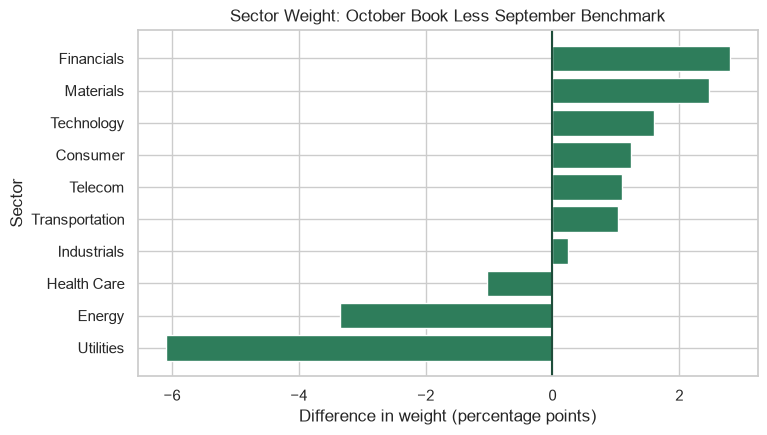

In [77]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(sector_weights.index, sector_weights['difference'])
ax.axvline(0, color='#1E4D3A')
ax.set_title('Sector Weight: October Book Less September Benchmark')
ax.set_xlabel('Difference in weight (percentage points)')
ax.set_ylabel('Sector')
plt.show()

In [78]:
check('Question 8.6 sector', answer_8_6a, 'e05a276ee4ce')
check('Question 8.6 difference', answer_8_6b, '94f45bd1b9ed', places=2)

Question 8.6 sector: correct
Question 8.6 difference: correct


Financials has the largest positive difference, 2.79 percentage points, and Utilities the largest negative, -6.09.
The book is as of 2026-10-30 and the benchmark 2026-09-30, so the differences mix positions with a month of price changes.

### 8.7 Book Less Benchmark, by Bucket

        book_pct  benchmark_pct  difference
bucket                                     
AAA         2.51           1.24        1.27
AA          3.34           3.62       -0.28
A          30.27          29.15        1.12
BBB        28.92          31.61       -2.69
BB         23.03          21.11        1.92
B           9.03          11.65       -2.62
CCC         2.90           1.62        1.28
grade
High Yield          34.38
Investment Grade    65.62
Name: weight_pct, dtype: float64


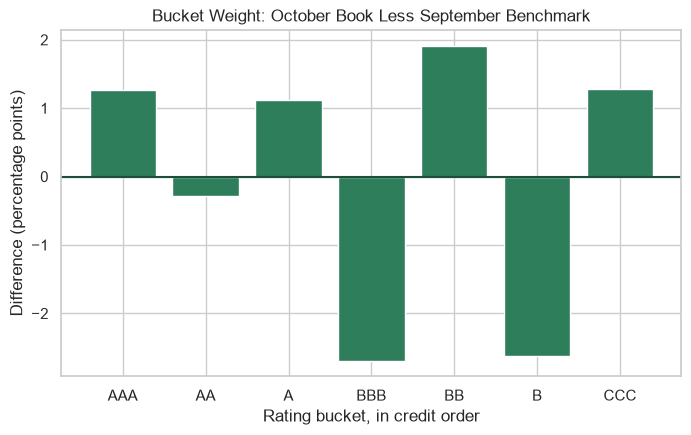

In [79]:
benchmark_rated = pd.merge(benchmark, ratings, on='rating', how='left', validate='many_to_one')
bucket_weights = pd.DataFrame({
    'book_pct': book.groupby('bucket')['weight_pct'].sum(),
    'benchmark_pct': benchmark_rated.groupby('bucket')['weight_pct'].sum(),
}).loc[bucket_order]
bucket_weights['difference'] = bucket_weights['book_pct'] - bucket_weights['benchmark_pct']
print(bucket_weights.round(2))
print(benchmark_rated.groupby('grade')['weight_pct'].sum().round(2))
answer_8_7 = round(bucket_weights.loc['BBB', 'difference'], 2)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(bucket_weights.index, bucket_weights['difference'])
ax.axhline(0, color='#1E4D3A')
ax.set_title('Bucket Weight: October Book Less September Benchmark')
ax.set_xlabel('Rating bucket, in credit order')
ax.set_ylabel('Difference (percentage points)')
plt.show()

In [80]:
check('Question 8.7', answer_8_7, '0088be0fdc01', places=2)

Question 8.7: correct


BBB is -2.69 percentage points and B -2.62; BB is the largest positive, 1.92.
By grade the differences nearly cancel: High Yield is 34.96 percent of the book against 34.38 of the benchmark.

### 8.8 The Ten Largest DTS Contributions

In [81]:
top_dts = book.nlargest(10, 'dts_contribution')
answer_8_8 = round(top_dts['dts_contribution'].sum() / book_dts * 100, 1)
print(answer_8_8, round(top_dts['weight_pct'].sum(), 2))
top_dts[['cusip', 'ticker', 'rating', 'oas', 'duration', 'dts', 'weight_pct',
         'dts_contribution']].round(2)

22.2 6.96


,cusip,ticker,rating,oas,duration,dts,weight_pct,dts_contribution
115,99066OAD2,NEVN,B-,744,6.00,4462.5,0.80,35.87
134,99038MAE9,PRAN,CCC+,884,4.97,4389.9,0.77,33.63
197,99036KAA3,XANL,CCC,607,5.67,3440.5,0.66,22.84
149,99046UAA9,SKEN,B+,371,5.91,2192.6,0.98,21.56
86,99004EAB3,HLVF,B+,414,10.17,4209.1,0.49,20.83
136,99145PAA0,PRAR,B-,489,4.96,2423.0,0.85,20.68
17,99009JAA9,CLDB,B,1403,4.48,6285.4,0.30,18.67
135,99038MAF6,PRAN,CCC+,1008,6.45,6504.6,0.27,17.80
39,99002CAB9,DNMR,BB+,170,11.65,1981.2,0.89,17.61
11,99033HAF2,CLAE,BBB-,155,11.88,1841.7,0.94,17.22


In [82]:
check('Question 8.8', answer_8_8, '7e51df81fab2', places=1)

Question 8.8: correct


The ten carry 22.2 percent of the book's DTS on 6.96 percent of its weight; nine are High Yield.
The table says where the DTS sits on 2026-10-30, not what any of the ten is worth.

### 8.9 High Yield Share of Bonds, by Sector

In [83]:
book['is_hy'] = (book['grade'] == 'High Yield').astype(int)
# count() is the bonds, sum() the 1s, and mean() the share of 1s
hy_by_sector = book.groupby('sector')['is_hy'].agg(['count', 'sum', 'mean'])
hy_by_sector['mean'] = hy_by_sector['mean'] * 100
hy_by_sector = hy_by_sector.sort_values('mean', ascending=False)
print(hy_by_sector.round(1))
answer_8_9a = round(hy_by_sector['mean'].iloc[0], 1)
answer_8_9b = hy_by_sector['count'].iloc[0]

                count  sum  mean
sector                          
Telecom            25   15  60.0
Materials          27   12  44.4
Technology         14    6  42.9
Transportation     22    9  40.9
Consumer           24    9  37.5
Industrials        19    7  36.8
Financials         27    8  29.6
Health Care        18    5  27.8
Energy             16    3  18.8
Utilities          14    2  14.3


In [84]:
check('Question 8.9 highest share', answer_8_9a, '11ebeef038cb', places=1)
check('Question 8.9 bonds', answer_8_9b, '0bbdc4781486', places=0)

Question 8.9 highest share: correct
Question 8.9 bonds: correct


Telecom has the highest share, 15 of its 25 bonds, 60.0 percent; the book as a whole is 76 of 206.
In a sector of 14 bonds one bond moves the rate by 7.1 points, so a rate is read with its count.

## 9 The Deliverables

### 9.1 The Workbook

In [85]:
report_file = 'project_report.xlsx'
# one workbook, two sheets; the sector table keeps its labels, the sector names
with pd.ExcelWriter(report_file) as writer:
    book.to_excel(writer, sheet_name='book', index=False)
    by_sector.to_excel(writer, sheet_name='summary')
book_back = pd.read_excel(report_file, sheet_name='book', dtype={'cusip': str})
summary_back = pd.read_excel(report_file, sheet_name='summary')
assert round(book_back['market_value'].sum(), 2) == expected_value, 'book sheet is off'
answer_9_1a = len(book_back)
answer_9_1b = len(summary_back)
os.remove(report_file)
answer_9_1c = os.path.exists(report_file)
print(book_back.shape, summary_back.shape, answer_9_1c)

(206, 26) (10, 4) False


In [86]:
check('Question 9.1 book sheet', answer_9_1a, '15e830c9779f', places=0)
check('Question 9.1 summary sheet', answer_9_1b, '08f770846638', places=0)
check('Question 9.1 file left behind', answer_9_1c, '9c3d5c576030')

Question 9.1 book sheet: correct
Question 9.1 summary sheet: correct
Question 9.1 file left behind: correct


The book sheet came back with 206 rows and 26 columns and the cover note's market value; the summary sheet has the 10 sectors.
The workbook holds values, not formulas, and it is deleted here because the course removes what it writes; on a desk it is the file that is sent.

### 9.2 The AI-Use Log

A model log, to show the level of detail.

<table align="left">
<tr><th align="left">What I asked</th><th align="left">What I kept or rejected</th><th align="left">How I checked it</th></tr>
<tr><td align="left">How to test that every value in a text column is exactly nine capital letters or digits</td><td align="left">Accepted <code>.str.fullmatch()</code> with <code>[A-Z0-9]{9}</code>; rejected <code>.str.contains()</code>, which passes a longer value holding nine good characters</td><td align="left">Ran both on four typed values: one good, one lower case, one of ten characters, one of eight</td></tr>
<tr><td align="left">How to fill a missing value from two other columns of the same row</td><td align="left">Accepted <code>fillna()</code> given a column; rejected filling with the column's mean</td><td align="left">Tested the rule on the 202 rows with an OAS: it gave the file's value every time</td></tr>
<tr><td align="left">How to write two tables to two sheets of one workbook</td><td align="left">Accepted <code>pd.ExcelWriter</code> with one <code>to_excel</code> per sheet</td><td align="left">Read both sheets back and compared the row counts and the market value</td></tr>
</table>
<br clear="left">

No row of the extract went into the assistant: each question described the columns and the task.

### 9.3 A Model Page

**Month-end picture of the book, 2026-10-30.** All names are invented.

**The book in five numbers.** The book holds 206 bonds of 113 issuers with a market value of 509.93 million dollars on 507.25 million of face.

Weighted by market value, the average OAS is 181.3 basis points, the average duration is 6.08 years, and the average rating score is 9.22, between BBB and BBB-.

**Concentrations.** Materials is the largest sector at 14.34 percent of market value, then Financials at 13.72 and Telecom at 12.80.

Investment Grade is 65.04 percent and High Yield 34.96 percent.

The ten largest issuers are 21.44 percent of the book and the largest position is 1.07 percent.

The DTS of the book is 1,022.3 years times basis points; High Yield carries 57.29 percent of it, and the ten bonds with the largest contributions carry 22.2 percent on 6.96 percent of the weight.

**Data quality.** The extract had 209 rows against 206 in the cover note.

3 exact duplicate rows were removed.

9 sector names with the wrong case or a stray space were tidied, taking 19 sector values to 10.

2 face amounts with the wrong sign were made positive, 3 prices in the wrong units were corrected, and 1 maturity dated 2019 was replaced with the benchmark's 2029 date.

4 missing OAS values were worked out from DTS and spread duration.

The corrected table matches all three control totals.

Identifiers, ratings, and price dates were checked and are clean.

18 bonds flagged by the IQR rule on OAS are real and were kept.

**Against the benchmark.** The benchmark file is dated 2026-09-30, a month before the book.

By sector, the largest positive difference in weight is Financials, 2.79 percentage points, and the largest negative is Utilities, -6.09.

By rating bucket, BBB is -2.69 and BB is 1.92.

High Yield is 0.58 points above the benchmark's 34.38 percent.

**Open items.** Operations to confirm the 6 corrected values and the 4 worked-out OAS values, and to say why 3 rows were sent twice.

An October benchmark file is needed to compare the two on the same date.

## The Report to the Desk

The six fixes are 4.1's decisions and `clean_extract` applies them in one call; the seventh row is 6.3's decision.

The planted problems are listed in `data/project_answer_key.md`, and they match.

<table align="left">
<tr><th align="left">#</th><th align="left">Finding</th><th align="left">How it was found</th><th align="left">Rows</th><th align="left">What was done</th><th align="left">Effect</th></tr>
<tr><td align="left">1</td><td align="left">Rows sent twice</td><td align="left">rows against the cover note, <code>duplicated()</code></td><td align="left">3</td><td align="left">removed the copies</td><td align="left">market value down 6,301,370.00 dollars to the control total</td></tr>
<tr><td align="left">2</td><td align="left">Sector names with the wrong case or a stray space</td><td align="left"><code>isin()</code> against the benchmark's names</td><td align="left">9</td><td align="left">tidied</td><td align="left">19 sector values became 10</td></tr>
<tr><td align="left">3</td><td align="left">Face held with a negative sign</td><td align="left">rule 3</td><td align="left">2</td><td align="left">made positive</td><td align="left">face up 6,500,000 dollars to the control total</td></tr>
<tr><td align="left">4</td><td align="left">Prices in the wrong units</td><td align="left">rule 5, the tie-out</td><td align="left">3</td><td align="left">multiplied or divided by 100</td><td align="left">all 206 rows tie out</td></tr>
<tr><td align="left">5</td><td align="left">Maturity before the as-of date</td><td align="left">rule 4</td><td align="left">1</td><td align="left">the benchmark's maturity</td><td align="left">earliest maturity 2027-10-02</td></tr>
<tr><td align="left">6</td><td align="left">OAS missing</td><td align="left"><code>isna().sum()</code></td><td align="left">4</td><td align="left">worked out from DTS and spread duration</td><td align="left">mean OAS 190.21 over 202 bonds became 190.09 over 206</td></tr>
<tr><td align="left">7</td><td align="left">Very wide spreads</td><td align="left">the IQR rule on OAS</td><td align="left">18</td><td align="left">kept: real bonds</td><td align="left">none; 7.62 percent of market value</td></tr>
</table>
<br clear="left">

Checked and found clean: every CUSIP's shape and its place in the benchmark, tickers, ratings against the scale, prices, coupons, and durations above zero, face against amount outstanding, and price dates.